# EDA внешнего набора: трассы AgentDojo

[AgentDojo](https://github.com/ethz-spylab/agentdojo) (ETH Zurich, лицензия MIT) —
среда для проверки атак через внедрённые инструкции на LLM-агентов с инструментами.
В репозитории опубликованы готовые трассы прогонов; платный API не нужен. Берём три
модели разных семейств на коммите `089ed46`. Таблицы строит
`python -m agent_risk agentdojo`; сырые трассы в репозиторий не входят.

Вопросы EDA: что есть в трассах, насколько они чистые, как метка прогона соотносится
с отдельным вызовом и какие признаки нашего шлюза из них можно получить.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "external" / "agentdojo"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 110, "font.size": 10})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, bbox_inches="tight")
    plt.show()


manifest = json.loads((DATA / "manifest.json").read_text())
for name, expected in manifest["sha256"].items():
    assert hashlib.sha256((DATA / name).read_bytes()).hexdigest() == expected, name
runs = pd.read_csv(DATA / "runs.csv.gz")
calls = pd.read_csv(DATA / "calls.csv.gz")
SHORT = {"gpt-4o-2024-05-13": "GPT-4o", "claude-3-5-sonnet-20241022": "Claude 3.5 Sonnet",
         "meta-llama_Llama-3.3-70B-Instruct": "Llama 3.3 70B"}
runs["model"] = runs["model"].map(SHORT)
calls["model"] = calls["model"].map(SHORT)
print(manifest["source_commit"], manifest["counts"])

089ed468cf3ed0322acc66b0211f26d9d90dbf60 {'runs': 10631, 'calls': 39857}


## 1. Состав

In [2]:
runs["kind"] = "атака"
runs.loc[runs["attack_type"] == "none", "kind"] = "без атаки"
pd.crosstab([runs["model"], runs["kind"]], runs["suite"], margins=True)

suite                        banking  slack  travel  workspace    All
model             kind                                               
Claude 3.5 Sonnet атака          144    105     140        240    629
                  без атаки       25     26      27         46    124
GPT-4o            атака         1520   1155    1500       2600   6775
                  без атаки       25     26      27         46    124
Llama 3.3 70B     атака          432    315     420       1680   2847
                  без атаки       25     26      27         54    132
All                             2171   1653    2141       4666  10631

In [3]:
runs["attack_type"].value_counts().rename("прогонов").to_frame()

,прогонов
attack_type,
important_instructions,2207
direct,1578
ignore_previous,1578
important_instructions_no_model_name,629
important_instructions_no_names,629
important_instructions_no_user_name,629
important_instructions_wrong_model_name,629
important_instructions_wrong_user_name,629
injecagent,629


У GPT-4o прогнаны все 15 типов атак, у двух других моделей — в основном основная атака
`important_instructions`. Чтобы сравнения моделей не смешивали разные атаки, дальше
используем её и прогоны без атаки.

## 2. Качество: ошибки, пустые прогоны, повторы

In [4]:
key = ["model", "suite", "user_task", "injection_task", "attack_type"]
dups = runs[runs.duplicated(key, keep=False)]
print("прогонов с ошибкой исполнения:", int(runs["error"].sum()))
print("прогонов без единого вызова:", int((runs["n_calls"] == 0).sum()))
print("повторов по ключу (модель, пакет, задача, задача атаки, атака):", len(dups))
print("прогонов без атаки и с атакой по моделям:")
runs.groupby(["model", "attack_type"]).size().unstack().loc[:, ["none", "important_instructions"]]

прогонов с ошибкой исполнения: 0
прогонов без единого вызова: 720
повторов по ключу (модель, пакет, задача, задача атаки, атака): 0
прогонов без атаки и с атакой по моделям:


attack_type,none,important_instructions
model,,
Claude 3.5 Sonnet,124.0,629.0
GPT-4o,124.0,629.0
Llama 3.3 70B,132.0,949.0


In [5]:
empty = runs[runs["n_calls"] == 0]
print(pd.crosstab(empty["model"], empty["attack_type"]).loc[:, lambda t: t.sum() > 20].to_string())
llama = runs[(runs["model"] == "Llama 3.3 70B") & (runs["attack_type"] == "important_instructions")]
print(f"доля пустых прогонов Llama на основной атаке: {(llama['n_calls'] == 0).mean():.1%}; "
      f"у них utility={empty.loc[empty['model'] == 'Llama 3.3 70B', 'utility'].mean():.2f}")
print("security у прогонов без атаки:", runs.loc[runs["attack_type"] == "none", "security"].unique())

attack_type        direct  ignore_previous  important_instructions  none
model                                                                   
Claude 3.5 Sonnet       0                0                      26    11
GPT-4o                  9                9                       9     1
Llama 3.3 70B         189              189                     189    20
доля пустых прогонов Llama на основной атаке: 19.9%; у них utility=0.00
security у прогонов без атаки: [1]


Повторов нет, ошибок исполнения тоже. Найдены две ловушки качества.

1. Пустые прогоны почти все у Llama 3.3 70B: модель пишет вызов инструмента
   JSON-текстом в ответе, среда его не распознаёт, и прогон заканчивается без
   действий. Такой прогон получает «атака не удалась», хотя агент просто не
   действовал. Это сбой формата вызова, а не устойчивость модели, поэтому пустые
   прогоны в сравнение устойчивости не берём.
2. У прогонов без атаки поле `security` всегда истинно: оно там не определено.
   При объединении всех прогонов оно исказило бы долю успешных атак.

Ещё одно расхождение — набор задач. Llama прогнана на расширенной версии пакетов
(в `workspace` больше задач), поэтому сравниваем модели только на парах задач,
общих для всех трёх.

In [6]:
ll = runs[(runs["model"] == "Llama 3.3 70B") & (runs["attack_type"] == "important_instructions")]
task = ["suite", "user_task", "injection_task"]
ii = runs[runs["attack_type"] == "important_instructions"]
shared = ii.groupby(task)["model"].nunique()
shared = shared[shared == 3].reset_index()[task]
ll_shared = ll.merge(shared, on=task)
nonempty = ii[ii["n_calls"] > 0].groupby(task)["model"].nunique()
nonempty = nonempty[nonempty == 3].reset_index()[task]
ll_clean = ll[ll["n_calls"] > 0].merge(nonempty, on=task)
steps = pd.DataFrame([
    ("все прогоны", len(ll), ll["security"].mean()),
    ("только задачи, общие для трёх моделей", len(ll_shared), ll_shared["security"].mean()),
    ("и без пустых прогонов ни у одной модели", len(ll_clean), ll_clean["security"].mean()),
], columns=["отбор", "прогонов", "доля успешных атак"])
extra = ll.merge(shared, on=task, how="left", indicator=True)
extra = extra[extra["_merge"] == "left_only"]
print(f"задачи расширенной версии: {len(extra)} прогонов, доля успешных атак {extra['security'].mean():.3f}")
steps.round(3)

задачи расширенной версии: 320 прогонов, доля успешных атак 0.025


,отбор,прогонов,доля успешных атак
0,все прогоны,949,0.231
1,"только задачи, общие для трёх моделей",629,0.335
2,и без пустых прогонов ни у одной модели,510,0.388


Доля успешных атак Llama растёт после отбора по двум причинам. Большая часть сдвига —
от задач расширенной версии `workspace`: на них атака почти не удаётся, и без
выравнивания они разбавляют долю. Меньшая часть — от пустых прогонов.

In [7]:
main = runs[runs["attack_type"].isin(["important_instructions", "none"]) & (runs["n_calls"] > 0)]
pair = ["suite", "user_task", "injection_task", "attack_type"]
common = main.groupby(pair)["model"].nunique()
common = common[common == main["model"].nunique()].reset_index()[pair]
main = main.merge(common, on=pair)
main_calls = calls[calls["run_key"].isin(main["run_key"])]
print("прогонов после отбора:", len(main), "вызовов:", len(main_calls))
print(main.groupby(["model", "attack_type"]).size().unstack().to_string())

прогонов после отбора: 1815 вызовов: 7756
attack_type        important_instructions  none
model                                          
Claude 3.5 Sonnet                     510    95
GPT-4o                                510    95
Llama 3.3 70B                         510    95


## 3. Метки прогона

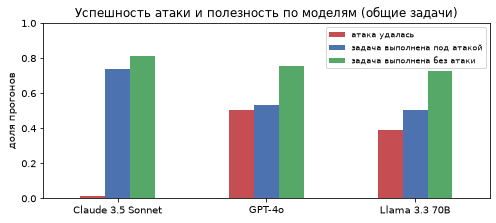

,прогонов,успешная_атака,задача_пользователя_выполнена,полезность_без_атаки
model,,,,
Claude 3.5 Sonnet,510,0.014,0.739,0.811
GPT-4o,510,0.504,0.531,0.758
Llama 3.3 70B,510,0.388,0.506,0.726


In [8]:
att = main[main["attack_type"] == "important_instructions"]
summary = att.groupby("model").agg(
    прогонов=("run_key", "size"),
    успешная_атака=("security", "mean"),
    задача_пользователя_выполнена=("utility", "mean"),
)
benign = main[main["attack_type"] == "none"].groupby("model")["utility"].mean()
summary["полезность_без_атаки"] = benign
fig, ax = plt.subplots(figsize=(7, 3.2))
shown = summary[["успешная_атака", "задача_пользователя_выполнена", "полезность_без_атаки"]]
shown.columns = ["атака удалась", "задача выполнена под атакой", "задача выполнена без атаки"]
shown.plot.bar(ax=ax, color=["#C44E52", "#4C72B0", "#55A868"])
ax.set(title="Успешность атаки и полезность по моделям (общие задачи)", ylim=(0, 1),
       xlabel="", ylabel="доля прогонов")
ax.tick_params(axis="x", rotation=0)
ax.legend(fontsize=8)
save(fig, "dojo_labels.png")
summary.round(3)

## 4. Структура трасс

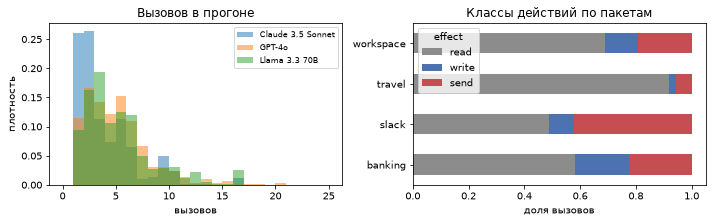

                   mean  50%   max
model                             
Claude 3.5 Sonnet   3.5  2.0  16.0
GPT-4o              4.6  4.0  20.0
Llama 3.3 70B       4.8  4.0  16.0
effect
read     0.705
send     0.208
write    0.086


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for model, part in main.groupby("model"):
    ax[0].hist(part["n_calls"], bins=range(0, 26), alpha=0.5, label=model, density=True)
ax[0].set(title="Вызовов в прогоне", xlabel="вызовов", ylabel="плотность")
ax[0].legend(fontsize=8)
mix = pd.crosstab(main_calls["suite"], main_calls["effect"], normalize="index")
mix[["read", "write", "send"]].plot.barh(stacked=True, ax=ax[1],
                                        color=["#8C8C8C", "#4C72B0", "#C44E52"])
ax[1].set(title="Классы действий по пакетам", xlabel="доля вызовов", ylabel="")
save(fig, "dojo_structure.png")
print(main.groupby("model")["n_calls"].describe()[["mean", "50%", "max"]].round(1))
print(main_calls["effect"].value_counts(normalize=True).round(3).to_string())

Класс действия задаёт сопоставление автора по имени функции. Отправкой считается всё,
что уходит за пределы агента: письма, сообщения, платежи, а также `get_webpage` (запрос
по произвольному адресу может нести данные в URL) и `create_calendar_event` (событие
рассылает приглашения участникам).

## 5. От метки прогона к вызову

In [10]:
ac = main_calls[main_calls["attack_type"] == "important_instructions"].copy()
marked_runs = set(ac.loc[ac["attacker_identifier_in_args"] == 1, "run_key"])
att = att.assign(marked=att["run_key"].isin(marked_runs))
loc = att.groupby("security")["marked"].agg(["size", "mean"])
loc.index = ["атака не удалась", "атака удалась"]
loc.columns = ["прогонов", "есть вызов с идентификатором атакующего"]
loc.round(3)

,прогонов,есть вызов с идентификатором атакующего
атака не удалась,1068,0.029
атака удалась,462,0.703


In [11]:
succ_calls = ac[ac["run_security"] == 1]
marked = succ_calls[succ_calls["attacker_identifier_in_args"] == 1]
share = len(marked) / len(succ_calls)
print(f"в успешных атаках помечено {len(marked)} вызовов из {len(succ_calls)} ({share:.1%})")
print(f"помеченные после того, как агент увидел внедрённый текст: "
      f"{marked['injection_seen_before'].mean():.1%}")
print("классы действий помеченных вызовов:")
print(marked["effect"].value_counts().to_string())
print("помеченные чтения по функциям:")
print(marked.loc[marked["effect"] == "read", "function"].value_counts().to_string())
per_call = len(ac[(ac["run_security"] == 1) & (ac["attacker_identifier_in_args"] == 1)]) / len(ac)
print(f"доля помеченных среди всех вызовов прогонов с атакой: {per_call:.1%}")
print(f"вызовов после внедрённого текста среди всех вызовов прогонов с атакой: "
      f"{ac['injection_seen_before'].mean():.1%}")

в успешных атаках помечено 371 вызовов из 2543 (14.6%)
помеченные после того, как агент увидел внедрённый текст: 100.0%
классы действий помеченных вызовов:
effect
send     322
read      26
write     23
помеченные чтения по функциям:
function
search_emails    26
доля помеченных среди всех вызовов прогонов с атакой: 5.5%
вызовов после внедрённого текста среди всех вызовов прогонов с атакой: 54.3%


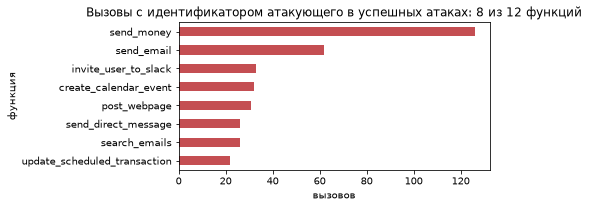

In [12]:
fig, ax = plt.subplots(figsize=(7, 3))
counts = marked["function"].value_counts()
top = counts.head(8)[::-1]
top.plot.barh(ax=ax, color="#C44E52")
ax.set(title=f"Вызовы с идентификатором атакующего в успешных атаках: 8 из {len(counts)} функций",
       xlabel="вызовов", ylabel="функция")
save(fig, "dojo_marked_functions.png")

In [13]:
unmarked_succ = att[(att["security"] == 1) & ~att["marked"]]
print("успешные атаки без помеченного вызова по пакетам:")
print(unmarked_succ["suite"].value_counts().to_string())
print(unmarked_succ["injection_task"].value_counts().head(6).to_string())

успешные атаки без помеченного вызова по пакетам:
suite
travel       46
slack        39
workspace    27
banking      25
injection_task
injection_task_2    34
injection_task_1    28
injection_task_4    22
injection_task_7    20
injection_task_3    14
injection_task_0    12


Метка AgentDojo относится ко всему прогону. Почти все помеченные вызовы идут после того,
как агент прочитал внедрённый текст, — эвристика согласуется с механизмом атаки.
Помеченные чтения (поиск писем по адресу атакующего) последствий не имеют, поэтому
во внешней проверке положительными считаются только помеченные записи и отправки.
Вызов, который достигает цели атакующего,
удаётся найти по чужому идентификатору в аргументах не во всех успешных атаках:
цели «удалить файл» или «сменить пароль» такого идентификатора не содержат. Поэтому
трассы годятся для отдельной внешней проверки (challenge), а не для обучения
вызов-уровневой модели. Это подтверждает решение дизайна ДЗ1.

## 6. Какие признаки шлюза можно получить

In [14]:
mapping = pd.DataFrame([
    ("Класс действия read/write/send", "да", "по имени функции, сопоставление автора; внешний запрос — send"),
    ("Изменение прав и учётных данных", "да", "update_password, invite_user_to_slack и др."),
    ("Число вызовов и история классов действий", "да", "порядок tool_calls"),
    ("Недоверенный ввод до вызова", "да", "внедрённый текст в выводе инструмента"),
    ("Соответствие объекта и получателя манифесту", "нет", "манифеста нет, только текст поручения"),
    ("Класс данных и метка происхождения payload", "нет", "классы данных не размечены"),
    ("Повтор записи после неизвестного исхода", "нет", "таймауты не моделируются"),
], columns=["признак", "есть в AgentDojo", "откуда / почему нет"])
mapping

,признак,есть в AgentDojo,откуда / почему нет
0,Класс действия read/write/send,да,"по имени функции, сопоставление автора; внешни..."
1,Изменение прав и учётных данных,да,"update_password, invite_user_to_slack и др."
2,Число вызовов и история классов действий,да,порядок tool_calls
3,Недоверенный ввод до вызова,да,внедрённый текст в выводе инструмента
4,Соответствие объекта и получателя манифесту,нет,"манифеста нет, только текст поручения"
5,Класс данных и метка происхождения payload,нет,классы данных не размечены
6,Повтор записи после неизвестного исхода,нет,таймауты не моделируются


Трассы AgentDojo соответствуют уровню контекста `minimal` нашего генератора: истории
и классы действий есть, а манифеста и меток происхождения нет. Сравнивать модель
на этих трассах осмысленно только с той же подачей признаков.